# Company-name harmonisation

**Goal.** Patent applicants appear under many spellings (`NOKIA CORPORATION`, `NOKIA (DEUTSCHLAND)`, `NOKIA MOBILE PHONES LIMITED`, ...). The notebook groups the spellings that refer to the same organisation and gives each group one representative name, so that patent counts and concentration measures refer to organisations and not to spellings.

**Method.** We follow the three-stage structure of Terrorizer (Ascione & Sterzi, 2024): *parsing* (name cleaning), *matching* (a similarity weight for every pair of names) and *filtering* (a graph of names, cut into communities with Louvain). No step is learned from labels: the gold standard is used only to **evaluate** the result, never to choose the threshold.

| Stage | Where | What it does |
|---|---|---|
| Parsing | `clean()` | Normalises and standardises every name |
| Matching | `score_pairs()` | Gives **every** pair of cleaned names a weight in [0, 1] |
| Filtering | `otsu()` + `cluster()` | Keeps the strong edges (Otsu threshold), finds communities (Louvain), names each community |
| Evaluation | `precision_recall_f1()` | Pairwise precision / recall / F1 against the gold standard |

**Structure.** *Part 1* builds and evaluates the pipeline on the labelled gold standard. *Part 2* applies the **same, unchanged** pipeline to the **firms** of the quantum-computing sample and writes a CSV with the name before and after harmonisation, to be validated separately. Universities, government / non-profit bodies and individuals are **not** harmonised in Part 2.

In [1]:
# %pip install sentence-transformers networkx matplotlib
import re, unicodedata
from difflib import SequenceMatcher
from itertools import combinations
from math import comb
from pathlib import Path
import numpy as np
import pandas as pd
import networkx as nx
import networkx.algorithms.community as nx_comm
import matplotlib.pyplot as plt
from sentence_transformers import SentenceTransformer

# ---- Config ----
GOLD_FILE = 'PATSTAT_500_label_datav4.csv'   # gold standard: raw names + true group
NAME_COL, GROUP_COL = 'comp', 'Group'        # raw-name column and true-group column (evaluation only)
EMBEDDING_MODEL = "Vsevolod/company-names-similarity-sentence-transformer"   # embedding model built for company names

# Edge weight = weighted average of three similarities; coefficients >= 0 and sum to 1, so the weight cannot exceed 1
SCORE_WEIGHTS = {"cosine": 0.55, "jaccard": 0.30, "edit": 0.15}
SCORE_FLOOR = 0.35                           # pairs below this weight are never edges (also the lower end of Otsu's pool)
LOUVAIN_RESOLUTION = 1.0                     # library default (also Terrorizer's starting value)
LOUVAIN_SEED = 42                            # Louvain is randomised: a fixed seed makes every run identical
SWEEP_GRID = np.arange(0.40, 0.851, 0.025)   # thresholds tried in the stability check

## Part 1 - Pipeline, built and evaluated on the gold standard

### Step 1 - Parsing: name cleaning

Two spellings can be compared fairly only after trivial differences (case, accents, punctuation, legal forms) are removed. `clean()` is deterministic and deliberately **conservative**: it never deletes words from the middle of a name. In order, it:

1. **Normalises Unicode** (NFKC/NFKD): full-width characters are folded (`ＮＴＴ -> NTT`), Latin accents removed (`MÜLLER -> MULLER`), CJK characters left intact.
2. **Keeps the Latin version** of mixed names (a CJK name followed by its Latin transliteration).
3. **Removes noise**: care-of addresses (`C/O ...`), dots and symbols (`S.P.A. -> SPA`) and Latin / CJK legal forms (`INC`, `GMBH`, `株式会社`, ...), but only at the very start or end of the name.
4. **Standardises** frequent words (`UNIVERSITY -> UNIV`, `TECHNOLOGIES -> TECH`, ...) and drops filler words (`OF`, `THE`, `DE`, ...).

*Country names are intentionally not removed.* A trailing country is often part of the institution's name; stripping it made different institutions identical (`University of Hong Kong` and `University of Iceland` both became `UNIV`). The step scored well on the gold standard but is harmful in a sector with many universities, so it was dropped.

The word lists are hand-written from common conventions (Magerman et al., 2006; Callaert et al., 2011); nothing is learned from data.

In [2]:
# Legal forms, removed ONLY at the start or end of a name ("ACME INC" -> "ACME"); words inside a name are never touched
FORMS = ["INC", "INCORPORATED", "LLC", "LLP", "LP", "LTD", "LIMITED", "CORP", "CORPORATION", "CO", "COMPANY", "PLC", "GMBH", "MBH",
         "AG", "KG", "SE", "SA", "SAS", "SARL", "SRL", "SPA", "SL", "BV", "NV", "OY", "OYJ", "AB", "AS", "ASA", "APS", "PTY", "PTE",
         "KK", "KABUSHIKI KAISHA", "SP Z OO", "OOO", "BHD", "SDN", "PVT", "LTDA"]
FORMS_RE = "|".join(sorted(FORMS, key=len, reverse=True))     # longest first: "CORPORATION" before "CO", "INCORPORATED" before "INC"
FORMS_CJK = "股份有限公司|有限责任公司|有限責任公司|有限公司|株式会社|有限会社|合同会社|주식회사|公司"   # CJK equivalents of "Co., Ltd."
# Frequent institutional words (and their spellings in other languages) mapped to one short form
WORDS = {"UNIVERSITY": "UNIV", "UNIVERSITAET": "UNIV", "UNIVERSITAT": "UNIV", "UNIVERSITE": "UNIV", "UNIVERSIDAD": "UNIV",
         "UNIVERSITA": "UNIV", "INSTITUTE": "INST", "INSTITUT": "INST", "INSTITUTO": "INST", "TECHNOLOGY": "TECH",
         "TECHNOLOGIES": "TECH", "TECHNOLOGICAL": "TECH", "LABORATORY": "LAB", "LABORATORIES": "LAB", "LABS": "LAB",
         "CENTRE": "CENTER", "SCIENCES": "SCIENCE", "大學": "大学"}
FILLER = {"OF", "THE", "FOR", "AND", "DE", "DI", "DU", "DES", "ET", "UND"}   # words with no identifying power, dropped everywhere


def clean(name):
    # 1. NFKC folds full-width letters/ligatures, .upper() makes it case-insensitive, NFKD splits accented letters;
    #    combining accents after a Latin character are dropped (MÜLLER -> MULLER), those on CJK/Korean characters are kept
    s = unicodedata.normalize("NFKD", unicodedata.normalize("NFKC", str(name)).upper())
    s = unicodedata.normalize("NFC", "".join(c for i, c in enumerate(s) if not (unicodedata.combining(c) and s[i - 1] < "ɐ")))
    # 2. Noise: patent-office markers, question marks (characters lost in PATSTAT), dots and apostrophes
    s = re.sub(r"[▲▼?.'’]", "", s)
    # 3. If a non-ASCII (e.g. CJK) name is followed by a Latin version with >= 3 letters, keep only the Latin version
    latin = re.search(r"[^\x00-\x7f]([A-Z0-9][A-Z0-9 ,&\-/]+)$", s)
    if latin and len(re.sub(r"[^A-Z]", "", latin.group(1))) >= 3:
        s = latin.group(1)
    # 4. Cut "C/O ..." (care-of); "A/S" -> "AS"; "&" -> " AND " so that "A&B" and "A AND B" coincide
    s = re.sub(r"\bC/O\b.*$", "", s).replace("A/S", "AS").replace("&", " AND ")
    # 5. Punctuation -> spaces, then remove a CJK legal form at the very start or end
    s = re.sub(rf"^({FORMS_CJK})|({FORMS_CJK})$", "", re.sub(r"[^\w ]|_", " ", s).strip())
    # 6. Standardise frequent words and drop filler words ("or s" keeps the name if everything was filtered out)
    s = " ".join(WORDS.get(w, w) for w in s.split() if w not in FILLER) or s
    # 7. Strip Latin legal forms at the start/end, also when repeated ("ACME CO LTD" -> "ACME")
    return re.sub(rf"^(({FORMS_RE}) )+|( ({FORMS_RE}))+$", "", s).strip() or s

### Step 2 - Matching: all pairs of names

Each cleaned name is mapped to a unit-length vector by a sentence-embedding model fine-tuned on company names (SBERT-type; Reimers & Gurevych, 2019). **Every** pair of names is scored, so no true pair can be lost before scoring and no blocking parameter has to be justified (with *n* names there are *n(n-1)/2* pairs: ~4.4 million for the gold standard, ~1.4 million for the quantum firms). For much larger name sets blocking would be needed.

The edge weight of names *a* and *b* is a weighted average of three complementary similarities:

$$w_{ab} = 0.55\,\cos(a,b) + 0.30\,J(a,b) + 0.15\,E(a,b)$$

| Component | What it captures |
|---|---|
| `cosine` (embeddings) | semantic / orthographic closeness |
| `J` (Jaccard on words) | share of words in common, order ignored |
| `E` (`difflib` ratio) | letter-by-letter similarity |

The coefficients are non-negative and sum to 1, so $w_{ab}\le 1$; only pairs with $w_{ab}\ge 0.35$ (`SCORE_FLOOR`) become candidate edges, hence every edge weight lies in [0.35, 1]. Most weight goes to the embeddings; the letter-based terms keep the pipeline from relying on the model alone. The coefficients are fixed constants, **not optimised** on the gold standard.

In [3]:
model = SentenceTransformer(EMBEDDING_MODEL)

def score_pairs(names):
    "Edge weight of ALL pairs of (sorted, distinct) cleaned names; returns only the pairs with weight >= SCORE_FLOOR."
    emb = model.encode(names, normalize_embeddings=True, show_progress_bar=False).astype(np.float32)   # one unit vector per name
    cos = emb @ emb.T                                                    # cosine of every pair (unit vectors -> dot product)
    words = [set(n.split()) for n in names]
    w = SCORE_WEIGHTS
    rows = []
    for i, j in combinations(range(len(names)), 2):                      # i < j, names sorted -> name_a < name_b
        union = words[i] | words[j]
        jac = len(words[i] & words[j]) / len(union) if union else 0.0    # Jaccard on words
        edit = SequenceMatcher(None, names[i], names[j]).ratio()         # letter-by-letter ratio
        s = w["cosine"] * float(cos[i, j]) + w["jaccard"] * jac + w["edit"] * edit
        if s >= SCORE_FLOOR:
            rows.append((names[i], names[j], s))
    scored = pd.DataFrame(rows, columns=["name_a", "name_b", "score"])
    assert abs(sum(w.values()) - 1) < 1e-9 and scored["score"].between(SCORE_FLOOR, 1 + 1e-6).all(), "edge weights out of range"
    return scored

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

### Step 3 - Filtering: threshold, communities, representative name

* **Threshold (Otsu, 1979).** Computed from the weights themselves: the cut that splits their histogram into two classes (accidental similarities vs genuine matches) with the largest between-class variance. It uses no labels and is recomputed on every dataset, so the pipeline runs on a new sector without a gold standard. Its pool is restricted to weights >= `SCORE_FLOOR`, so the huge mass of unrelated pairs does not dominate. (Terrorizer sets its threshold empirically and then tunes it on labelled data.)
* **Communities.** Names are nodes, pairs with weight >= threshold are weighted edges; Louvain (Blondel et al., 2008) maximises modularity and needs no number of groups. Resolution = 1 (default), fixed seed.
* **Representative name.** The most frequent name of the community (ties: the shortest). Frequency = number of rows in the gold standard, number of **patent families** in the quantum sample.

In [4]:
def otsu(scores, bins=100, floor=SCORE_FLOOR):
    "Otsu's threshold: the cut with the largest between-class variance of the weights (no labels)."
    hist, edges = np.histogram(scores[scores >= floor], bins=bins)
    centers = (edges[:-1] + edges[1:]) / 2.0
    w1, w2 = np.cumsum(hist), np.cumsum(hist[::-1])[::-1]                       # pairs at or below / at or above each bin
    m1 = np.cumsum(hist * centers) / np.maximum(w1, 1)                          # class means for every candidate cut
    m2 = (np.cumsum((hist * centers)[::-1]) / np.maximum(w2[::-1], 1))[::-1]
    return float(centers[np.argmax(w1[:-1] * w2[1:] * (m1[:-1] - m2[1:]) ** 2)])

def cluster(names, scored, th, seed=LOUVAIN_SEED):
    "Louvain communities of the name graph (edges: weight >= th); isolated names stay alone."
    G = nx.Graph()
    G.add_nodes_from(names)
    e = scored[scored["score"] >= th]
    G.add_weighted_edges_from(zip(e["name_a"], e["name_b"], e["score"]))
    return nx_comm.louvain_communities(G, weight="weight", resolution=LOUVAIN_RESOLUTION, seed=seed)

def representative_map(communities, freq):
    "name -> most frequent name of its community (ties: shortest)."
    m = {}
    for members in communities:
        rep = min(members, key=lambda n: (-freq.get(n, 0), len(n)))
        m.update({x: rep for x in members})
    return m

def harmonise(names, freq):
    "Matching + filtering on a list of distinct cleaned names. Returns (scored pairs, threshold, communities, name -> representative)."
    scored = score_pairs(names)
    th = otsu(scored["score"].values)
    comms = cluster(names, scored, th)
    return scored, th, comms, representative_map(comms, freq)

def pairs_inside(sizes):
    return sum(comb(int(n), 2) for n in sizes)

def precision_recall_f1(gold, pred):
    "Pairwise metrics (course definition): a pair counts if both names are in the same group."
    t = pd.DataFrame({"gold": list(gold), "pred": list(pred)})
    tp = pairs_inside(t.groupby(["gold", "pred"]).size())
    tp_fp, tp_fn = pairs_inside(t.groupby("pred").size()), pairs_inside(t.groupby("gold").size())
    p, r = (tp / tp_fp if tp_fp else 1.0), (tp / tp_fn if tp_fn else 0.0)
    return {"groups found": t["pred"].nunique(), "precision": p, "recall": r, "F1": 2 * p * r / (p + r) if p + r else 0.0}

### Evaluation on the gold standard

The pipeline is run with the unsupervised Otsu threshold. The cell then sweeps the threshold over a grid to check **stability**: the "best on grid" threshold is picked on the gold standard itself, so it is an optimistic upper bound and is never used. The gap F1(best) - F1(Otsu) is the price of choosing the threshold without labels; a flat curve around Otsu's value and a small spread across Louvain seeds mean the result is not sensitive to either choice.

names: 2,981 | pairs: 4,441,690 | true groups: 481
edges kept (weight >= 0.35): 81,692 | Otsu threshold: 0.566 | communities: 559 (largest: 170 names)
groups found    559.000
precision         0.920
recall            0.861
F1                0.890
Otsu 0.566: F1 0.890 | best on grid 0.475: F1 0.915 | loss 0.025 | Louvain seeds 0-9: F1 mean 0.890, sd 0.000


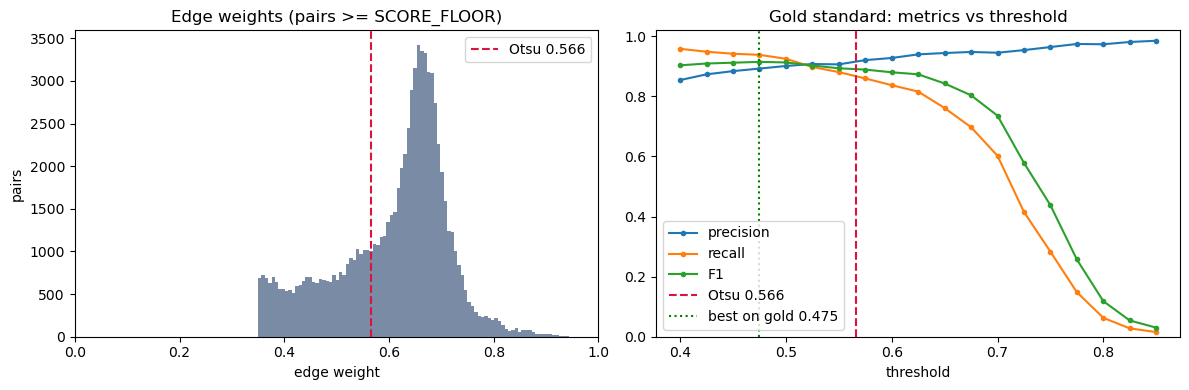

In [5]:
df = pd.read_csv(GOLD_FILE)
df["clean"] = df[NAME_COL].apply(clean)
df = df[df["clean"].str.len() > 0].copy()
names = sorted(df["clean"].unique())                                   # sorted: reproducible
print(f"names: {len(names):,} | pairs: {len(names) * (len(names) - 1) // 2:,} | true groups: {df[GROUP_COL].nunique()}")

scored, th, comms, rep = harmonise(names, df["clean"].value_counts())
df["harmonized"] = df["clean"].map(rep)
print(f"edges kept (weight >= {SCORE_FLOOR}): {len(scored):,} | Otsu threshold: {th:.3f} | communities: {len(comms):,} (largest: {max(map(len, comms))} names)")
print(pd.Series(precision_recall_f1(df[GROUP_COL], df["harmonized"])).round(3).to_string())

# stability: threshold sweep and Louvain seeds
f1_at = lambda t, seed=LOUVAIN_SEED: precision_recall_f1(df[GROUP_COL], df["clean"].map({n: i for i, c in enumerate(cluster(names, scored, t, seed)) for n in c}))
sweep = pd.DataFrame([{"th": round(float(t), 3), **f1_at(t)} for t in SWEEP_GRID])
best, at_otsu = sweep.loc[sweep["F1"].idxmax()], f1_at(th)
seeds = [f1_at(th, s)["F1"] for s in range(10)]
print(f"Otsu {th:.3f}: F1 {at_otsu['F1']:.3f} | best on grid {best['th']:.3f}: F1 {best['F1']:.3f} | loss {best['F1'] - at_otsu['F1']:.3f} "
      f"| Louvain seeds 0-9: F1 mean {np.mean(seeds):.3f}, sd {np.std(seeds):.3f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(scored["score"], bins=100, color="#7a8ba6")
ax[0].axvline(th, color="crimson", ls="--", label=f"Otsu {th:.3f}")
ax[0].set(title="Edge weights (pairs >= SCORE_FLOOR)", xlabel="edge weight", ylabel="pairs", xlim=(0, 1)); ax[0].legend()
for col in ("precision", "recall", "F1"):
    ax[1].plot(sweep["th"], sweep[col], marker="o", ms=3, label=col)
ax[1].axvline(th, color="crimson", ls="--", label=f"Otsu {th:.3f}")
ax[1].axvline(best["th"], color="green", ls=":", label=f"best on gold {best['th']:.3f}")
ax[1].set(title="Gold standard: metrics vs threshold", xlabel="threshold", ylim=(0, 1.02)); ax[1].legend()
plt.tight_layout(); plt.show()

## Part 2 - Quantum sector: firms only

Applies the pipeline above, **unchanged**, to the quantum-computing applicants and **keeps firms only**. Individuals, universities and government / non-profit organisations are excluded: the cleaning and matching stages were developed and evaluated on firm names, and adapting them to universities (names that differ only by a place) and to individuals (surnames) is future work. Everything created here lives in `qc` / `q_*` variables, so nothing from Part 1 is overwritten. Part 2 is **not validated here**: it ends with a CSV of the name before and after harmonisation, to be checked separately.

| Step | What happens |
|---|---|
| 1 | Load the applicants file (one row per patent family and applicant) |
| 2 | Assign every applicant a **type**: PATSTAT's `psn_sector` when known; fixed name rules when it is `UNKNOWN` or empty |
| 3 | Keep firms only |
| 4 | `clean()` -> `harmonise()` (same functions and settings as Part 1; communities are named after the spelling in most **families**) |
| 5 | Write the CSV: name before, cleaned name, name after |

**Applicant type for `UNKNOWN` sectors** (about one third of the applicants, mostly recent names PATSTAT has not classified yet). Fixed rules on the name, applied in this order, taken from the Eurostat method (Callaert et al., 2011): legal form -> company; university word -> university; institute / government word -> gov / non-profit; business word or `&` -> company; `SURNAME, Name` or 2-4 plain words -> individual; a single word -> company; anything else -> uncertain. A name is treated as an individual only if **both** `psn_name` and PATSTAT's harmonised `han_name` look like a person. The rules contain no parameters and are not fitted. The few `uncertain` names are left out together with the non-firms.

In [6]:
ENV = "PROD"
QC_CANDIDATES = [Path.home() / "Group15_innovation/outputs/step2_input" / f"qc_applicants_{ENV}.csv",   # project folder
                 Path(f"qc_applicants_{ENV}.csv")]                                                      # or next to the notebook
QC_FILE = next(p for p in QC_CANDIDATES if p.exists())
OUT_FILE = f"quantum_harmonised_{ENV}.csv"

qc = pd.read_csv(QC_FILE)                                      # `df` still holds the gold standard
print(f"{len(qc):,} rows | {qc['docdb_family_id'].nunique():,} families | {qc['psn_id'].nunique():,} applicants (psn_id)")
qc = qc[qc["psn_name"].str.upper().str.strip() != "-NOT AVAILABLE-"].copy()   # a missing name carries no information
print(f"after removing '-NOT AVAILABLE-': {len(qc):,} rows | {qc['psn_id'].nunique():,} applicants")

20,895 rows | 12,596 families | 6,056 applicants (psn_id)
after removing '-NOT AVAILABLE-': 20,883 rows | 6,055 applicants


In [7]:
# Applicant type: PATSTAT sector when known, name rules otherwise (fixed word lists; nothing is learned from the data)
LEGAL = ["INC", "LLC", "LLLP", "LL", "LTD", "LIMITED", "CORP", "CORPORATION", "CO", "COMPANY", "COPMANY", "GMBH", "AG", "SE",
         "SA", "SAS", "SARL", "SRL", "SPA", "SL", "BV", "NV", "NA", "OY", "AB", "AS", "ASA", "PTY", "PLC", "KK", "LLP", "LP",
         "PTE", "KG", "OOO", "SP Z OO", "SPOLKA", "JOINT.STOCK", "ANONIM SIRKETI", "OBSHCHESTVO"]
LEGAL_CJK = ["有限公司", "株式会社", "股份", "公司", "会社", "주식회사", "インコーポレイテッド", "アクチボラグ"]
UNIV = ["UNIV", "COLLEGE", "POLYTECHN", "POLITECNIC", "ECOLE", "HOCHSCHULE", "SCHOOL", "INSTITUTE OF TECHNOLOGY", "GIJUKU",
        "TRUSTEES", "EDUCATIONAL FUND", "大学", "大學", "学院", "カレッジ", "義塾", r"\bETH\b", r"\bEPFL\b", r"\bUESTC\b"]
GOV = ["INSTIT", "INSTYTUT", "INSTUTUC", "ИНСТИТУТ", "ACADEM", "COMMISSARIAT", "CNRS", "LABORATORY", "CENTER", "CENTRE",
       "CENTRUM", "ZENTRUM", "FOUNDATION", "FONDAZIONE", "FUNDACIO", "STIFTUNG", "FRAUNHOFER", "FROUNHAV", "PLANCK",
       "GOVERNMENT", "MINISTRY", "MINISTERIUM", "BUNDES", "FEDERATSIYA", "AGENTSTVO", "UCHREZHDENIE", "SECRETARY", "AGENCY",
       "COUNCIL", "CONSEJO", "CONSIGLIO", r"\bNATIONAL\b", "IDRYMA", "ASSOCIATION", "HOSPITAL", "ARMY", "AIR FORCE", "NAVY",
       "RIKEN", r"\bTNO\b", "NASA", "研究", "中心", "委员会", "科学院", "センター"]
FIRM = ["TECHNOLOG", "QUANT", "COMPUT", "SYSTEM", "SOLUTION", r"\bLABS?\b", "SOFTWARE", "NETWORK", "ELECTRONIC", "SEMICONDUCT",
        "PHOTONIC", "DEVICES", "INDUSTR", "HOLDING", "GROUP", "CAPITAL", "VENTURES", "ENTERPRISE", "INTERNATIONAL", "SCIENCE",
        "DIGITAL", "DATA", "INTELLIGEN", "ENERGY", "PHARMA", "SECUR", "MACHINES", "INSTRUMENTS", "ENGINEERING", "INNOVATION",
        "BLOCKCHAIN", "BANK", "INSURANCE", "PORTFOLIO", r"\bAI\b", "&", r"\+", "科技", "技术", "量子"]
LEGAL_RE = re.compile(r"\b(" + "|".join(LEGAL) + r")\b|" + "|".join(LEGAL_CJK))
UNIV_RE, GOV_RE, FIRM_RE = (re.compile("|".join(words)) for words in (UNIV, GOV, FIRM))
WORD = r"[^\W\d_]+(?:['\-][^\W\d_]+)*"                                 # letters only, any alphabet (O'NEIL, JEAN-PAUL)
PERSON_COMMA = re.compile(rf"^{WORD}( {WORD}){{0,3}} ?, ?{WORD}")       # 'SURNAME, Name'
PERSON_WORDS = re.compile(rf"^{WORD}( {WORD}){{1,3}}$")                 # 'LESCANNE Raphael', 'Taylor Lee Patti'

def normalise(name):
    "Upper case, no accents, full-width -> ASCII, no dots, no '?' (characters lost in PATSTAT)."
    s = unicodedata.normalize("NFKC", str(name))
    s = "".join(c for c in unicodedata.normalize("NFKD", s) if not unicodedata.combining(c)).upper()
    s = " ".join(s.replace("?", "").replace(".", "").split())
    return s.replace("UNIVERSITY CORPORATION", "UNIVERSITY")             # Japanese national universities

def type_from_name(name):
    "Type from the name alone (rules applied in this order)."
    n = normalise(name)
    if LEGAL_RE.search(n): return "company"
    if UNIV_RE.search(n):  return "university"
    if GOV_RE.search(n):   return "gov / non-profit"
    if FIRM_RE.search(n):  return "company"
    if PERSON_COMMA.match(n) or PERSON_WORDS.match(n) or "·" in n: return "individual"   # '·' separates Chinese transliterated names
    if len(n.split()) == 1: return "company"
    return "uncertain"

def type_from_names(psn_name, han_name):
    "Individual only if BOTH the applicant name and the harmonised PATSTAT name look like a person."
    t = type_from_name(psn_name)
    if t != "individual" or not isinstance(han_name, str): return t
    h = type_from_name(han_name)
    return t if h in ("individual", "uncertain") else h

def type_from_patstat(sector):
    s = str(sector).upper()
    if "UNIVERSITY" in s:             return "university"
    if "GOV" in s or "HOSPITAL" in s: return "gov / non-profit"
    if "COMPANY" in s:                return "company"
    if "INDIVIDUAL" in s:             return "individual"
    return None                                                        # UNKNOWN or empty

# one row per applicant (psn_id); PATSTAT type first, name rules only where the sector is UNKNOWN / empty
applicants = qc.groupby("psn_id").agg(psn_name=("psn_name", "first"), han_name=("han_name", "first"), psn_sector=("psn_sector", "first"))
applicants["type"] = applicants["psn_sector"].map(type_from_patstat)
unknown = applicants["type"].isna()
applicants.loc[unknown, "type"] = [type_from_names(a, b) for a, b in zip(applicants.loc[unknown, "psn_name"], applicants.loc[unknown, "han_name"])]
qc["type"] = qc["psn_id"].map(applicants["type"])

# firms only
qc_firms = qc[qc["type"] == "company"].copy()
print(f"UNKNOWN / empty sector classified by name rules: {unknown.sum():,} of {len(applicants):,} applicants")
print(applicants["type"].value_counts().to_string())
print(f"\nfirms only: rows {len(qc):,} -> {len(qc_firms):,} | families {qc['docdb_family_id'].nunique():,} -> {qc_firms['docdb_family_id'].nunique():,} "
      f"| applicants {qc['psn_id'].nunique():,} -> {qc_firms['psn_id'].nunique():,}")

UNKNOWN / empty sector classified by name rules: 2,902 of 6,055 applicants
type
company             2603
individual          2281
university           856
gov / non-profit     312
uncertain              3

firms only: rows 20,883 -> 13,160 | families 12,596 -> 8,980 | applicants 6,055 -> 2,603


In [8]:
# Same pipeline as Part 1: clean -> embeddings -> ALL pairs -> Otsu -> Louvain -> representative name (most families, then shortest)
qc_firms["clean"] = qc_firms["psn_name"].apply(clean)
qc_firms = qc_firms[qc_firms["clean"].str.len() > 0].copy()
q_names = sorted(qc_firms["clean"].unique())
q_fam = qc_firms.groupby("clean")["docdb_family_id"].nunique()          # families per cleaned name (names the communities)

q_scored, q_th, q_comms, q_map = harmonise(q_names, q_fam)
qc_firms["harmonised"] = qc_firms["clean"].map(q_map)
print(f"names: {len(q_names):,} | pairs: {len(q_names) * (len(q_names) - 1) // 2:,} | edges kept: {len(q_scored):,} | "
      f"Otsu threshold: {q_th:.3f} (gold standard {th:.3f})")

# output: one row per raw name, with its name before and after harmonisation (to be validated)
out = (qc_firms.groupby(["psn_name", "clean", "harmonised"]).agg(families=("docdb_family_id", "nunique")).reset_index()
               .rename(columns={"psn_name": "name_before", "clean": "name_clean", "harmonised": "name_after"})
               .sort_values(["name_after", "families"], ascending=[True, False]))
out.to_csv(OUT_FILE, index=False)
print(f"written {OUT_FILE}: {len(out):,} raw names -> {out['name_after'].nunique():,} organisations")

names: 1,665 | pairs: 1,385,280 | edges kept: 7,368 | Otsu threshold: 0.525 (gold standard 0.566)
written quantum_harmonised_PROD.csv: 2,184 raw names -> 1,073 organisations


,name_before,name_clean,name_after,families
2,01 COMMUNIQUE LABORATORY,01 COMMUNIQUE LAB,01 COMMUNIQUE LAB,4
3,01 Communique Laboratory Inc.,01 COMMUNIQUE LAB,01 COMMUNIQUE LAB,3
351,COMMUNIQUE LABORATORY,COMMUNIQUE LAB,01 COMMUNIQUE LAB,1
352,COMMUNIQUE LABORATORY INC.,COMMUNIQUE LAB,01 COMMUNIQUE LAB,1
7,1372934 B.C. Ltd.,1372934 BC,1372934 BC,16
6,1372934 B.C. LTD.,1372934 BC,1372934 BC,15
5,1372934 B.C. LTD,1372934 BC,1372934 BC,2
4,1372934 B. C. LTD.,1372934 B C,1372934 BC,1
8,1AHEAD TECHNOLOGIES,1AHEAD TECH,1AHEAD TECH,1
9,1QB INFORMATION TECHNOLOGIES,1QB INFORMATION TECH,1QB INFORMATION TECH,46


In [9]:
out.sort_values(by='families', ascending=False).head(20)

,name_before,name_clean,name_after,families
709,IBM (INTERNATIONAL BUSINESS MACHINES CORPORATION),IBM INTERNATIONAL BUSINESS MACHINES,IBM INTERNATIONAL BUSINESS MACHINES,772
1166,ORIGIN QUANTUM COMPUTING TECHNOLOGY (HEFEI) CO...,ORIGIN QUANTUM COMPUTING TECH HEFEI,ORIGIN QUANTUM COMPUTING TECH HEFEI,439
1170,ORIGIN QUANTUM COMPUTING TECHNOLOGY COMPANY,ORIGIN QUANTUM COMPUTING TECH,ORIGIN QUANTUM COMPUTING TECH HEFEI,431
164,BEIJING BAIDU NETCOM SCIENCE AND TECHNOLOGY CO...,BEIJING BAIDU NETCOM SCIENCE TECH,BEIJING BAIDU NETCOM SCIENCE TECH,331
563,GOOGLE,GOOGLE,GOOGLE,242
991,MICROSOFT TECHNOLOGY LICENSING,MICROSOFT TECH LICENSING,MICROSOFT TECH LICENSING,241
527,FUJITSU,FUJITSU,FUJITSU,227
393,D-WAVE SYSTEMS,D WAVE SYSTEMS,D WAVE SYSTEMS,212
2123,国际商业机器公司,国际商业机器,国际商业机器,201
712,IBM DEUTSCHLAND,IBM DEUTSCHLAND,IBM INTERNATIONAL BUSINESS MACHINES,173


## Design choices and limitations

**Choices.** The threshold is derived from the data (Otsu) and the Louvain resolution is the default (1); the three weights, `SCORE_FLOOR`, the histogram bins and the cleaning dictionaries are fixed and **not optimised** on the gold standard. The pipeline is deterministic (sorted names, fixed seed, no other randomness). Part 2 reuses Part 1 without any change, except that the Otsu threshold and the communities are recomputed on the quantum firms (both are label-free) and communities are named by number of families.

**Differences from Terrorizer** (Ascione & Sterzi, 2024): no hyper-parameter is tuned on labels (Terrorizer tunes nine with TPE, maximising F1); Louvain runs once, without the bridgeness-centrality pruning and re-clustering; the community is named after its most frequent name, not the one with the highest average cosine; only names are used (no locations to boost edge weights).

**Limitations**
- The gold standard was available during development, so its scores are a development benchmark, not a blind test. It was not built for any specific sector.
- Pairwise precision and recall are dominated by the largest groups; Louvain at a single resolution can merge distinct organisations that share a word (chain merges), so the largest communities should be inspected.
- No sensitivity analysis on the three weights, `SCORE_FLOOR` or the histogram bins.
- The embedding model is third-party and its training data are not documented, so an overlap with the evaluation names cannot be excluded.
- The quantum output is **not validated** in this notebook: it must be checked on the CSV (name before / after).

## References

- Ascione, G. S., & Sterzi, V. (2024). *Presenting Terrorizer: an algorithm for consolidating company names in patent assignees.* arXiv:2403.12083.
- Blondel, V. D., Guillaume, J.-L., Lambiotte, R., & Lefebvre, E. (2008). Fast unfolding of communities in large networks. *J. Stat. Mech.*, 2008(10), P10008.
- Callaert, J., du Plessis, M., Grouwels, J., Lecocq, C., Magerman, T., Peeters, B., Song, X., Van Looy, B., & Vereyen, C. (2011). *Patent statistics at Eurostat: Methods for regionalisation, sector allocation and name harmonisation.* Eurostat Methodologies & Working Papers.
- Magerman, T., Van Looy, B., & Song, X. (2006). *Data production methods for harmonised patent statistics: Patentee name harmonisation.* Eurostat Working Papers and Studies.
- Otsu, N. (1979). A threshold selection method from gray-level histograms. *IEEE Trans. Systems, Man, and Cybernetics*, 9(1), 62-66.
- Ratcliff, J. W., & Metzener, D. E. (1988). Pattern matching: the Gestalt approach. *Dr. Dobb's Journal*, July 1988 (basis of `difflib.SequenceMatcher`).
- Reimers, N., & Gurevych, I. (2019). Sentence-BERT: Sentence embeddings using Siamese BERT-networks. *EMNLP-IJCNLP 2019*.
- Unicode Consortium. *Unicode Standard Annex #15: Unicode Normalization Forms.* https://unicode.org/reports/tr15/
- Vsevolod. *company-names-similarity-sentence-transformer* (model card, Hugging Face).